# Load useful librairies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

 We first have a look at the dataset to see if there is any irregularities

In [ ]:
data = pd.read_csv("data.csv",sep = ",")

In [3]:
data.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [7]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIP Code,5000.0,93152.503000,2121.852197,9307.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


In [ ]:
## Minimum Experience is negative, will further investigate

min_exp = data[data["Experience"]<0]

In [9]:
print(min_exp.describe().T.to_markdown())

|                    |   count |         mean |         std |     min |      25% |     50% |       75% |     max |
|:-------------------|--------:|-------------:|------------:|--------:|---------:|--------:|----------:|--------:|
| ID                 |      52 |  2427.35     | 1478.83     |    90   |   767.25 |  2783.5 |  3669.5   |  4958   |
| Age                |      52 |    24.5192   |    1.47516  |    23   |    24    |    24   |    25     |    29   |
| Experience         |      52 |    -1.44231  |    0.639039 |    -3   |    -2    |    -1   |    -1     |    -1   |
| Income             |      52 |    69.9423   |   37.9553   |    12   |    40.75 |    65.5 |    86.75  |   150   |
| ZIP Code           |      52 | 93241        | 1611.65     | 90065   | 92167.8  | 93060   | 94720     | 95842   |
| Family             |      52 |     2.86538  |    0.970725 |     1   |     2    |     3   |     4     |     4   |
| CCAvg              |      52 |     2.12942  |    1.75056  |     0.2 |     1   

Negative experience seems to be distributed only across younger customers, this could mean this is not a bug in the data but  a deliberate choice. We leave this aside

### Question 1 : What is the conversion rate (percentage of clients that contracted a personal loan) of the marketing campaign?

In [10]:
# Considering each ID is unique, only need to look at the univariate analysis of the target variable
data["Personal Loan"].value_counts(normalize=True) * 100

Personal Loan
0    90.4
1     9.6
Name: proportion, dtype: float64

<Axes: xlabel='Personal Loan', ylabel='proportion'>

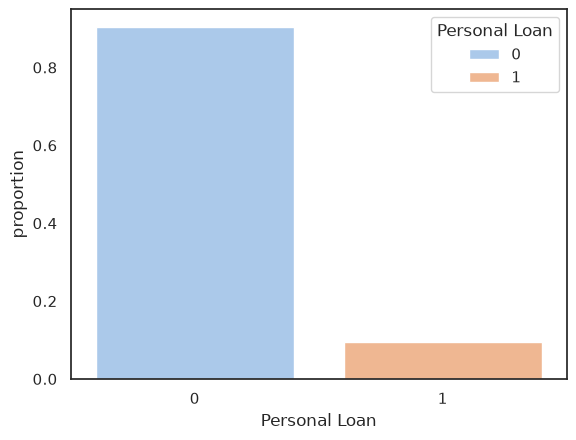

In [42]:
sns.set_style("white")
sns.set_palette(palette = "pastel")
sns.countplot(data= data,
             x = "Personal Loan", stat = "proportion", hue = "Personal Loan")

### Question 2 : How are the different variables (age, income, education, etc.) distributed in the dataset?


#### Distribution of Age

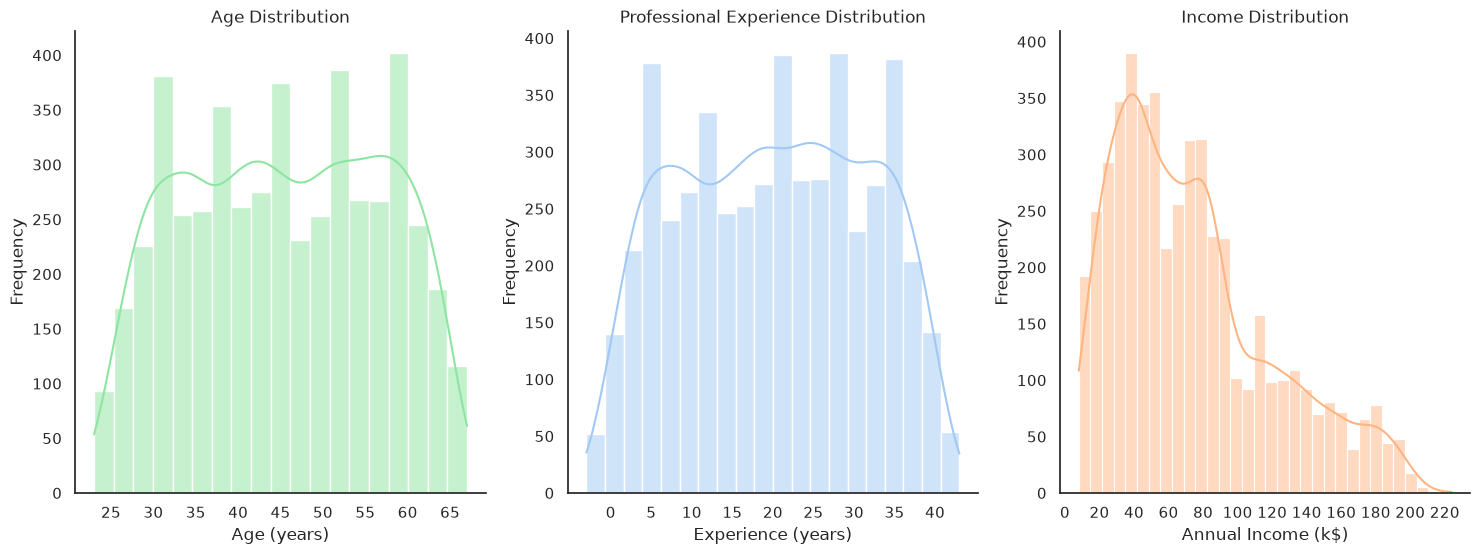

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
pastel = sns.color_palette("pastel")

sns.histplot(data['Age'], kde=True,ax=axes[0], color = pastel[2])
axes[0].set(title='Age Distribution',
       xlabel='Age (years)',
       ylabel='Frequency')
axes[0].set_xticks(np.arange(25, data['Age'].max(), 5))


sns.despine()


sns.histplot(data['Income'], kde=True, ax = axes[2], color = pastel[1])
axes[2].set(title='Income Distribution',
       xlabel='Annual Income (k$)',
       ylabel='Frequency')
axes[2].set_xticks(np.arange(0, data['Income'].max(), 20))

sns.histplot(data['Experience'], kde=True, ax = axes[1])
axes[1].set(title='Professional Experience Distribution',
       xlabel='Experience (years)',
       ylabel='Frequency')
axes[1].set_xticks(np.arange(0, data['Experience'].max(), 5))
sns.despine()



In [ ]:
# Recoding of Education variable to get "Undergduate","Graduate" and "Professional" labels.
data['Education_Label'] = data['Education'].map({1: 'Undergraduate', 2: 'Graduate', 3: 'Professional'})
data['Education_Label'].value_counts(normalize=True) * 100

Education_Label
Undergraduate    41.92
Professional     30.02
Graduate         28.06
Name: proportion, dtype: float64

/tmp/ipykernel_16381/826785922.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#d0bbff'` for the same effect.

  sns.countplot(data=data, x='Education_Label', hue='Education_Label', legend=True, ax=axes[0], color = pastel[4])
/tmp/ipykernel_16381/826785922.py:13: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#ffb482'` for the same effect.

  sns.countplot(data=data, x='Family', hue='Family', color = pastel[1], ax=axes[1])


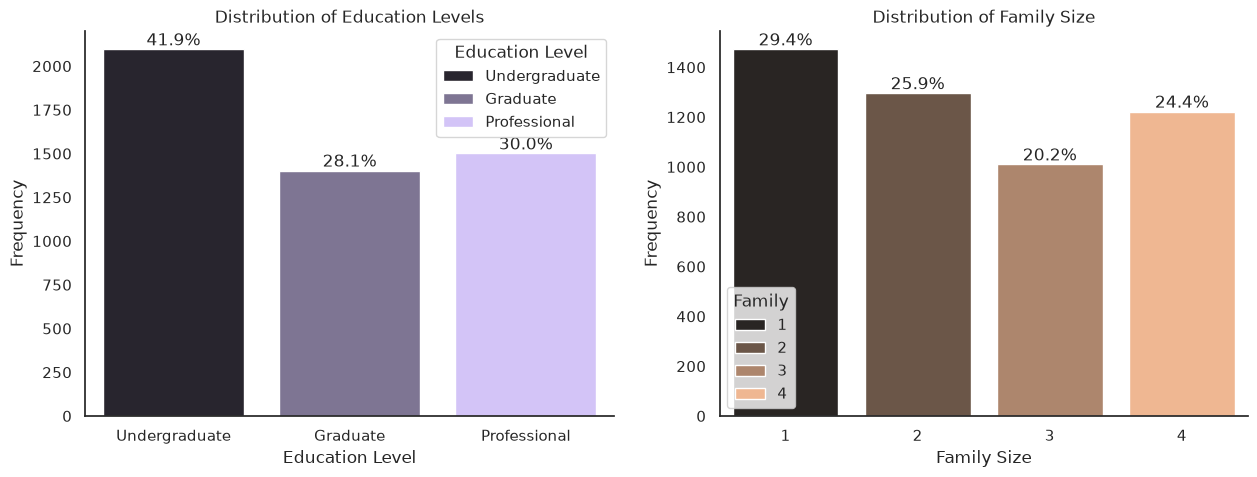

In [51]:
fig, axes = plt.subplots(1,2 ,figsize=(15, 5))
sns.countplot(data=data, x='Education_Label', hue='Education_Label', legend=True, ax=axes[0], color = pastel[4])
axes[0].set(title='Distribution of Education Levels', xlabel='Education Level', ylabel='Frequency')
axes[0].legend(title='Education Level')

# Display percentage labels
for container in axes[0].containers:
    labels = [f'{(bar.get_height() / data['Education_Label'].count() * 100):.1f}%' for bar in container]
    axes[0].bar_label(container, labels=labels)
sns.despine()


sns.countplot(data=data, x='Family', hue='Family', color = pastel[1], ax=axes[1])
axes[1].set(title='Distribution of Family Size', xlabel='Family Size', ylabel='Frequency')
sns.despine()

# Display percentage labels
for container in axes[1].containers:
    labels = [f'{(bar.get_height() / data["Family"].count() * 100):.1f}%' for bar in container]
    axes[1].bar_label(container, labels=labels)
sns.despine()



#### Distribution of Personal Loan, Securities Account, CD Account, Online and Credit Card


We recode the binary variables as boolean for simplicity. This helps us graph more accurate graphs.

In [53]:
# Recode binary variable names for better readability 
data = data.rename(columns={'CreditCard': 'Credit Card',
                              'Online': 'Online Facilities',
                              'CD Account': 'Certificate of Deposit Account'})
# Define all boolean variables
binary_cols = ['Personal Loan', 'Securities Account', 'Certificate of Deposit Account', 'Online Facilities', 'Credit Card']
# Melt the dataframe to long format for plotting
binary_df = data[binary_cols].melt(var_name='Variable', value_name='Response')
# Recode binary responses to 'Yes' and 'No' for better readability 
binary_df['Response'] = binary_df['Response'].map({0: 'No', 1: 'Yes'})

# Frequency table
counts_df = pd.crosstab(binary_df['Variable'], binary_df['Response'])
pct_df = pd.crosstab(binary_df['Variable'], binary_df['Response'], normalize='index') * 100
pd.concat([counts_df, pct_df.add_suffix(' (%)')], axis=1).round(1)

Response,No,Yes,No (%),Yes (%)
Variable,,,,
Certificate of Deposit Account,4698,302,94.0,6.0
Credit Card,3530,1470,70.6,29.4
Online Facilities,2016,2984,40.3,59.7
Personal Loan,4520,480,90.4,9.6
Securities Account,4478,522,89.6,10.4


/tmp/ipykernel_16381/321456605.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#d0bbff'` for the same effect.

  sns.countplot(data=binary_df, x='Variable', hue='Response', color = pastel[4], ax=ax)


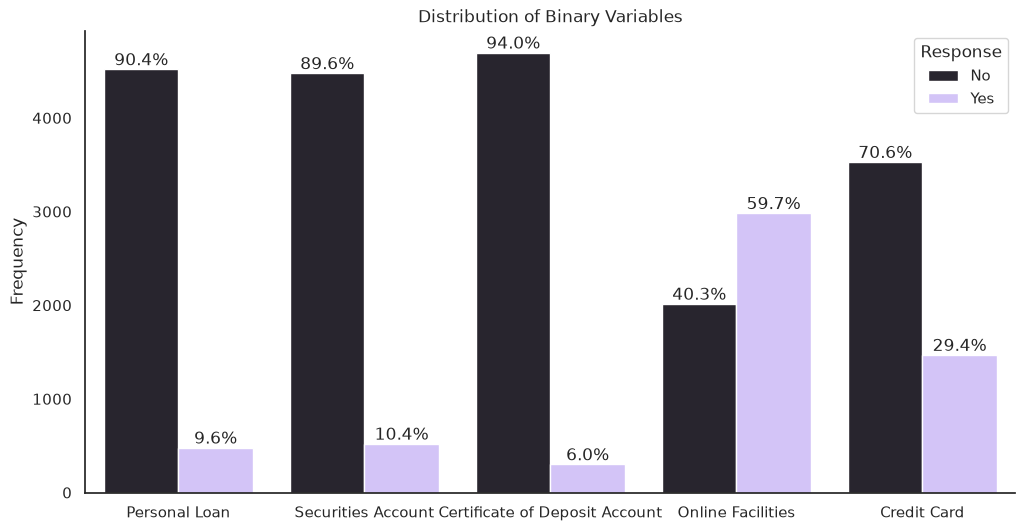

In [60]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.countplot(data=binary_df, x='Variable', hue='Response', color = pastel[4], ax=ax)
ax.set(title='Distribution of Binary Variables', xlabel=None, ylabel='Frequency')
sns.despine()

# Adding percentage labels to the bars
totals = [data[col].count() for col in binary_cols] # Total counts for each binary variable
for container in ax.containers:
    labels = [f'{(bar.get_height() / tot * 100):.1f}%' for bar, tot in zip(container, totals)]
    ax.bar_label(container, labels=labels)
plt.show()

### Question 3 : How do the different variables interact with each other?


<Axes: >

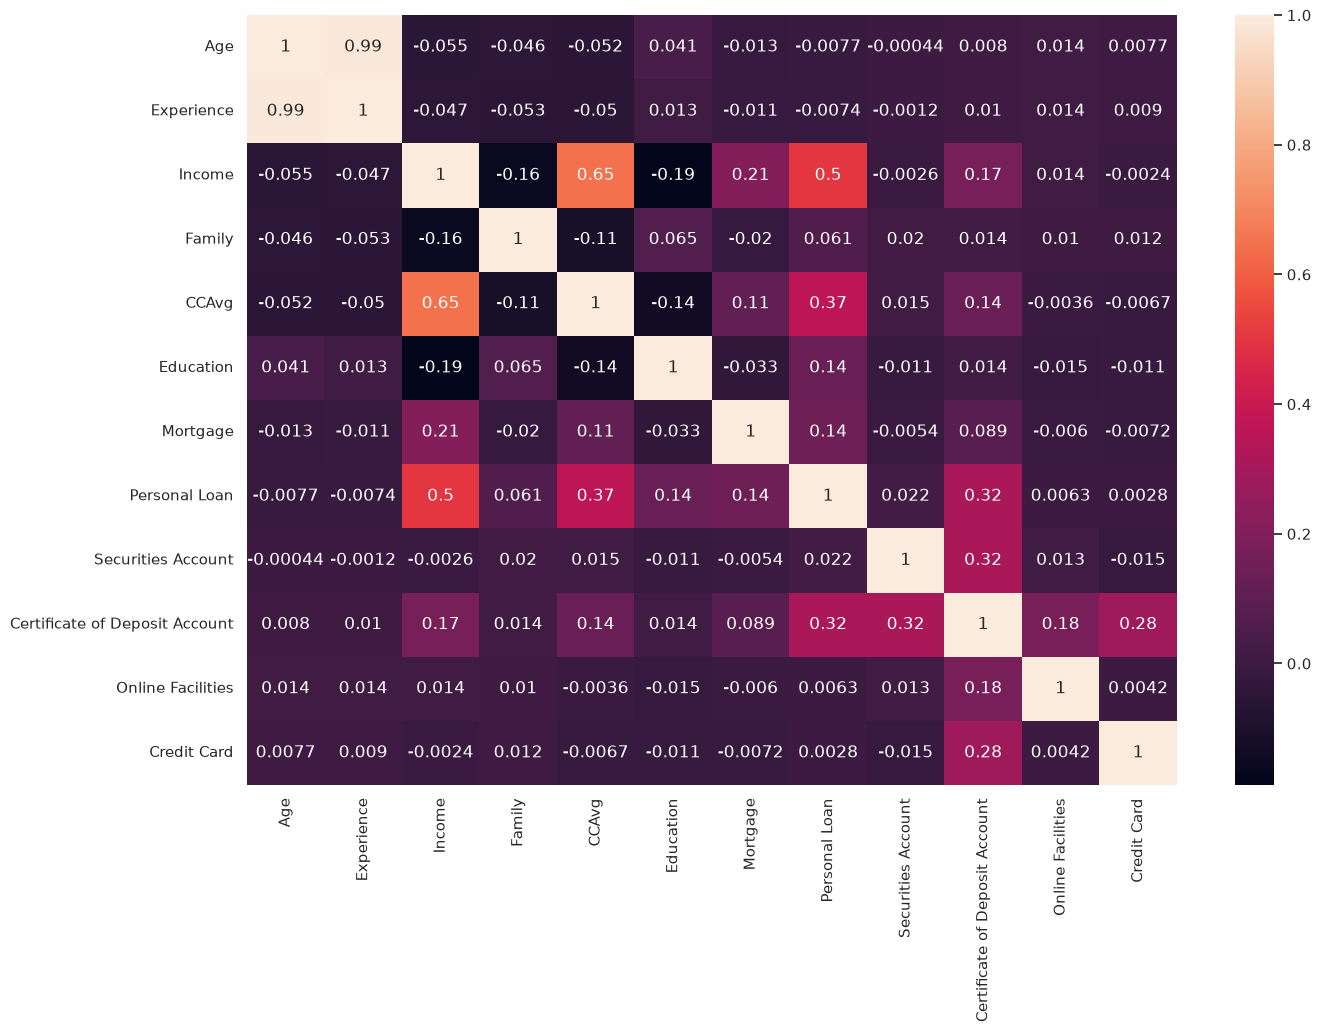

In [ ]:
#Correlation matrix to see which features are interesting to interact.
df_corr = data.drop(columns=['Education_Label', 'ID', 'ZIP Code']).copy()
corr = df_corr.corr()


plt.figure(figsize=(15,10))

sns.heatmap(corr,annot= True)

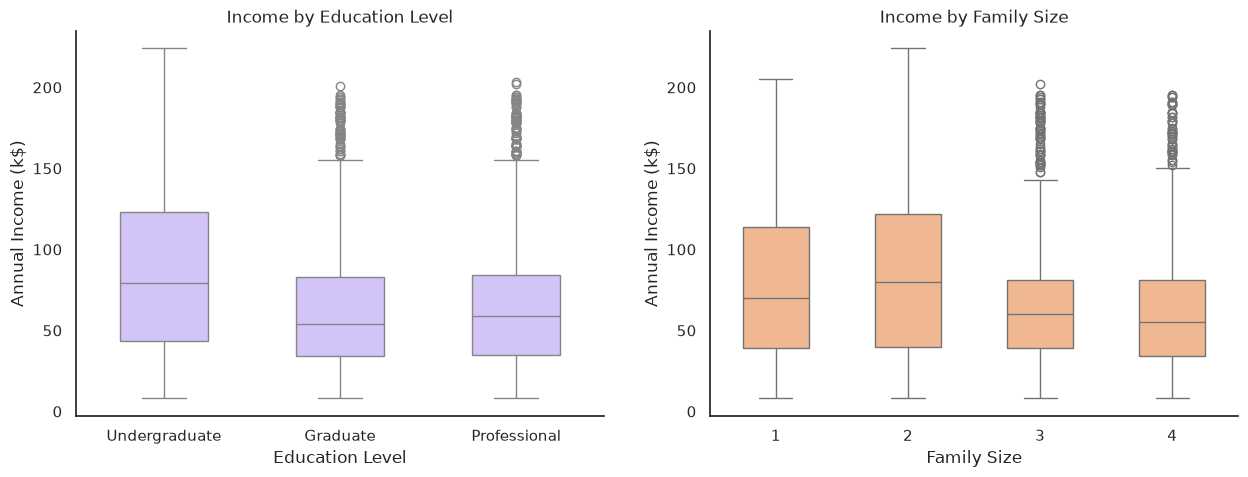

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=data, x="Education_Label", y="Income",
            color=pastel[4], width=0.5, ax=axes[0])
axes[0].set(title="Income by Education Level", xlabel="Education Level", ylabel="Annual Income (k$)")
sns.boxplot(data=data, x="Family", y="Income", color=pastel[1], width=0.5, ax=axes[1])
axes[1].set(title="Income by Family Size", xlabel="Family Size", ylabel="Annual Income (k$)")
sns.despine()


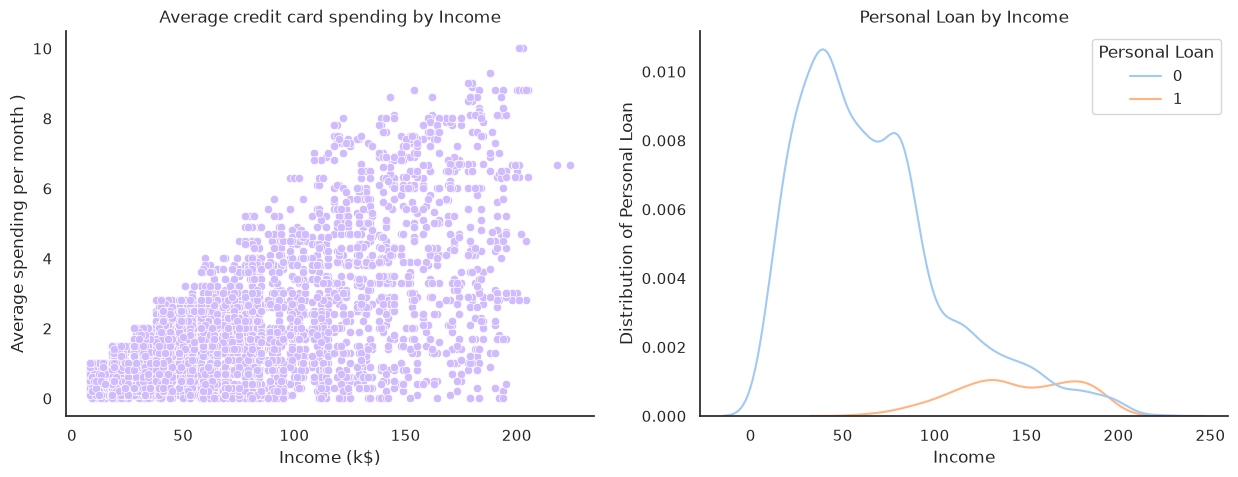

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=data, x="Income", y="CCAvg",
            color=pastel[4], ax=axes[0])
axes[0].set(title="Average credit card spending by Income", xlabel="Income (k$)", ylabel="Average spending per month )")
sns.kdeplot(data=data, x="Income", hue="Personal Loan", color=pastel[1],  ax=axes[1])
axes[1].set(title="Personal Loan by Income", xlabel="Income", ylabel="Distribution of Personal Loan")
sns.despine()

In [92]:
# The above graph suggests an investigation within the high income customers.
high = data[data["Income"] > 100]

### Question 4


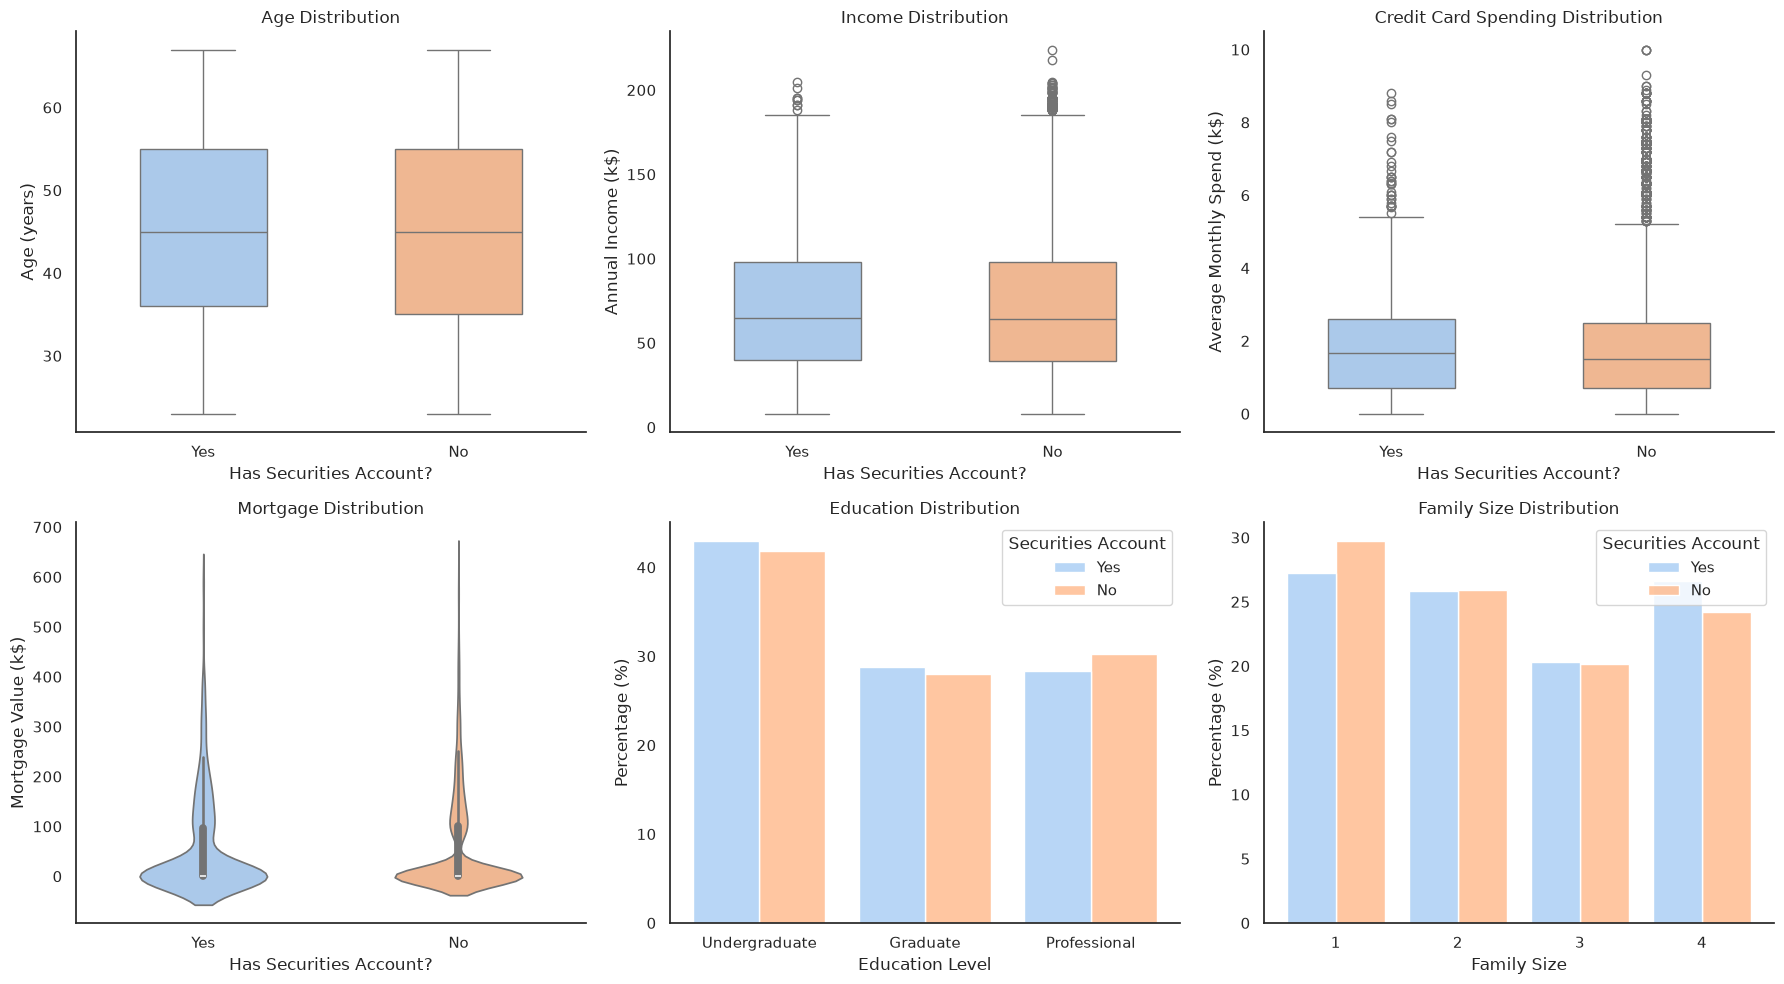

In [76]:
# Dataplot
plot_df = data.copy()
plot_df['Securities Account'] = plot_df['Securities Account'].map({0: 'No', 1: 'Yes'})

# Panel plot 
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Continuous variables
## Age
sns.boxplot(data=plot_df, x='Securities Account', y='Age', hue='Securities Account', legend=False,  width=0.5, ax=axes[0])
axes[0].set(title='Age Distribution', xlabel='Has Securities Account?', ylabel='Age (years)')
## Income
sns.boxplot(data=plot_df, x='Securities Account', y='Income', hue='Securities Account', legend=False,  width=0.5, ax=axes[1])
axes[1].set(title='Income Distribution', xlabel='Has Securities Account?', ylabel='Annual Income (k$)')
## Average Credit Card Spending
sns.boxplot(data=plot_df, x='Securities Account', y='CCAvg', hue='Securities Account', legend=False,  width=0.5, ax=axes[2])
axes[2].set(title='Credit Card Spending Distribution', xlabel='Has Securities Account?', ylabel='Average Monthly Spend (k$)')
## House Mortgage Value
sns.violinplot(data=plot_df, x='Securities Account', y='Mortgage', hue='Securities Account', legend=False,  width=0.5, ax=axes[3])
axes[3].set(title='Mortgage Distribution', xlabel='Has Securities Account?', ylabel='Mortgage Value (k$)')

# Categorical variables
## Education 
sns.histplot(data=plot_df, x='Education_Label', hue='Securities Account', multiple='dodge', stat='percent', common_norm=False, 
             shrink=0.8,  ax=axes[4])
axes[4].set(title='Education Distribution', xlabel='Education Level', ylabel='Percentage (%)')
## Family Size
sns.histplot(data=plot_df, x='Family', hue='Securities Account', multiple='dodge', stat='percent', common_norm=False, 
             discrete=True, shrink=0.8,  ax=axes[5])
axes[5].set(title='Family Size Distribution', xlabel='Family Size', ylabel='Percentage (%)')
axes[5].set_xticks(sorted(plot_df['Family'].unique()))

# Display
sns.despine()
plt.tight_layout()
plt.show()